# Part 1, step 2: train the deforestation detector

This notebook teaches a neural network to look at a 640 m square of land, seen from space in 2018 and again in 2023, and say whether the forest there was **stable** or **lost**.

It uses the 6,292 patches built in step 1 (`01_part1_build_patches.ipynb`). The network is a **ResNet-18**, a well-known image model that was first trained on millions of everyday photos. We adapt it to read 12 satellite bands (6 colours of light, before and after) and fine-tune it on our patches.

To check it honestly, whole areas of the map are kept aside for testing. The model never sees any patch from those areas during training, so the test score measures how well it works on places it has never seen.

**Outputs** (written to `outputs/`, used by the website): test accuracy and other scores, a confusion matrix picture, a map of the train and test areas, the training curve, and the test predictions with their locations. The trained weights go to `models/`, which is not committed to git.

## 1. Setup

Run the first cell once on a new computer, then restart the kernel. The second cell holds every setting in one place.

In [1]:
# Run once, then restart the kernel
%pip install torch torchvision scikit-learn pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 35.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchvision] [torchvision]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

PATCH_DIR = "../data/raw/part1_patches"          # the .npz files from step 1
INDEX_CSV = "../data/cleaned/part1_patch_index.csv"
OUT_DIR = "../outputs"                           # small results for the website
MODEL_DIR = "../models"                          # trained weights (*.pt is in .gitignore)

SEED = 42
SPLIT = (0.70, 0.15, 0.15)   # share of each country's patches for train, validation, test
BATCH_SIZE = 64
EPOCHS = 25                  # upper limit; training stops early when validation stops improving
PATIENCE = 5                 # epochs without improvement before stopping
LR = 3e-4                    # learning rate
WEIGHT_DECAY = 1e-4

BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]   # blue, green, red, near infrared, two shortwave infrared
CHANNELS = [f"{b}_{t}" for t in ("before", "after") for b in BANDS]   # the 12 input channels, in order

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available()       # Apple Silicon GPU
                      else "cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
print("Training on", device)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Training on mps


## 2. Load the patches

Each country file holds its patches as numbers: 12 bands of 64 × 64 pixels each. The index CSV adds where each patch is and which map block it belongs to.

In [3]:
index = pd.read_csv(INDEX_CSV)

Xs, ys, ids = [], [], []
for fname in sorted(os.listdir(PATCH_DIR)):
    if fname.endswith(".npz"):
        z = np.load(os.path.join(PATCH_DIR, fname), allow_pickle=True)
        Xs.append(z["X"]); ys.append(z["y"]); ids.extend(z["patch_id"].tolist())
X = np.concatenate(Xs)                      # (patches, 12, 64, 64), whole numbers (uint16)
meta = index.set_index("patch_id").loc[ids].reset_index()
y = meta["label"].to_numpy(np.int64)        # 0 = stable forest, 1 = forest lost

assert len(X) == len(meta) == len(index), "the .npz files and the index CSV disagree; rerun step 1 sections 7"
assert (np.concatenate(ys) == y).all(), "labels in the .npz files and the index CSV disagree"
assert meta["patch_id"].is_unique
print(f"{len(X)} patches, {X.shape[1]} bands of {X.shape[2]}x{X.shape[3]} pixels")
print(meta.groupby(["country", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

6292 patches, 12 bands of 64x64 pixels
label                             stable  lost
country                                       
Brazil                              1000  1000
Democratic Republic of the Congo    1000   516
India                                455   473
Indonesia                            946   902


## 3. Keep whole areas aside for testing

Patches next to each other look alike, so a random split would let the model "cheat" by memorising a neighbourhood. Instead, every patch belongs to a 1-degree map block (about 110 km across), and whole blocks go to one group only:

- **train**: the model learns from these
- **validation**: used during training to decide when to stop
- **test**: only used once, at the end, for the reported scores

The split is done per country, so every country appears in all three groups with both classes.

In [4]:
def split_blocks(meta, fractions, seed):
    rng = np.random.default_rng(seed)
    part = pd.Series("", index=meta.index)
    for country, g in meta.groupby("country"):
        blocks = g["block"].unique()
        rng.shuffle(blocks)
        share = g.groupby("block").size().loc[blocks].cumsum() / len(g)   # running share of patches
        names = np.where(share <= fractions[0], "train",
                         np.where(share <= fractions[0] + fractions[1], "val", "test"))
        part.loc[g.index] = g["block"].map(dict(zip(blocks, names)))
    return part

n_countries = meta["country"].nunique()
for attempt in range(200):
    meta["split"] = split_blocks(meta, SPLIT, SEED + attempt)
    classes = meta.groupby(["country", "split"])["label"].nunique()
    if len(classes) == n_countries * 3 and (classes == 2).all():
        break
else:
    raise RuntimeError("could not find a block split with both classes everywhere; lower the test share")

assert meta.groupby("block")["split"].nunique().max() == 1, "a block ended up in two groups"
tr = np.where(meta["split"] == "train")[0]
va = np.where(meta["split"] == "val")[0]
te = np.where(meta["split"] == "test")[0]
print(f"Split found on attempt {attempt + 1}: {len(tr)} train, {len(va)} validation, {len(te)} test")
print(meta.groupby(["country", "split", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

Split found on attempt 1: 4312 train, 930 validation, 1050 test
label                                   stable  lost
country                          split              
Brazil                           test      151   154
                                 train     690   701
                                 val       159   145
Democratic Republic of the Congo test      183    62
                                 train     648   383
                                 val       169    71
India                            test       98    84
                                 train     290   327
                                 val        67    62
Indonesia                        test      158   160
                                 train     668   605
                                 val       120   137


/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_35122/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_35122/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_35122/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplic

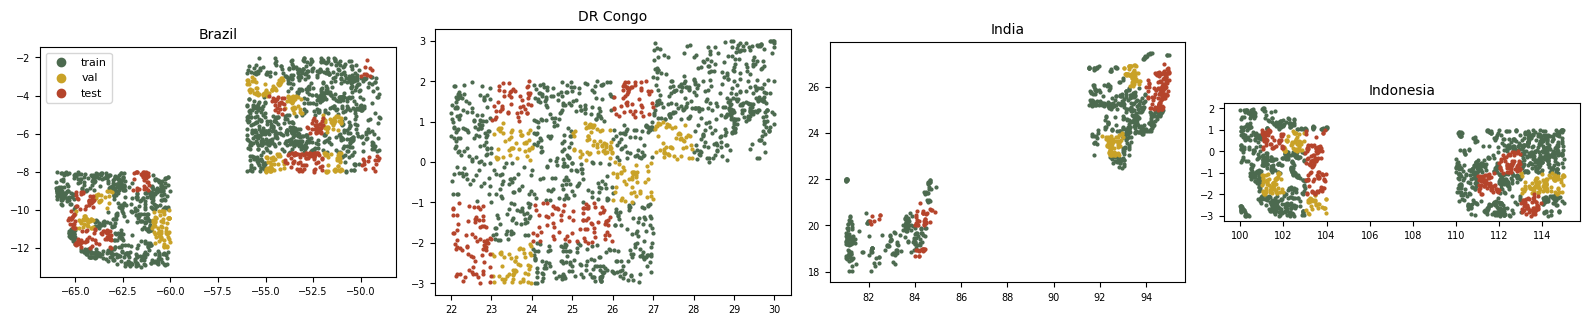

In [5]:
# Map of which areas went to which group (for the Data and Prep page)
colours = {"train": "#4c6a4f", "val": "#c9a227", "test": "#b5442b"}
countries = sorted(meta["country"].unique())
fig, axes = plt.subplots(1, len(countries), figsize=(4 * len(countries), 4), squeeze=False)
for ax, country in zip(axes[0], countries):
    g = meta[meta["country"] == country]
    for name, colour in colours.items():
        s = g[g["split"] == name]
        ax.scatter(s["lon"], s["lat"], s=4, c=colour, label=name)
    ax.set_title(country if len(country) < 20 else "DR Congo", fontsize=10)
    ax.set_aspect("equal"); ax.tick_params(labelsize=7)
axes[0, 0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part1_split_map.png"), dpi=150)
plt.show()

## 4. Scale the inputs and add variety

Each band is rescaled to an average of 0 and a spread of 1, using the training patches only. During training each patch is also turned and flipped at random, because a forest seen from above has no "right way up". This gives the model more variety without new data.

In [6]:
mean = np.array([X[tr, c].astype(np.float32).mean() for c in range(X.shape[1])], dtype=np.float32)
std = np.array([X[tr, c].astype(np.float32).std() for c in range(X.shape[1])], dtype=np.float32)
MEAN = torch.tensor(mean).view(1, -1, 1, 1).to(device)
STD = torch.tensor(std).view(1, -1, 1, 1).to(device)

def to_batch(idx, augment=False):
    xb = torch.from_numpy(X[idx].astype(np.float32)).to(device)
    xb = (xb - MEAN) / STD
    if augment:
        xb = torch.stack([torch.rot90(x, random.randint(0, 3), dims=(1, 2)) for x in xb])
        flip = torch.rand(len(xb), device=device) < 0.5
        xb[flip] = torch.flip(xb[flip], dims=(3,))
    return xb, torch.from_numpy(y[idx]).to(device)

print(pd.DataFrame({"mean": mean, "std": std}, index=CHANNELS).round(0))

              mean    std
B2_before    972.0  104.0
B3_before    836.0  102.0
B4_before    548.0  114.0
B8_before   2613.0  416.0
B11_before  1408.0  247.0
B12_before   559.0  143.0
B2_after    1011.0  111.0
B3_after     882.0  121.0
B4_after     602.0  159.0
B8_after    2649.0  439.0
B11_after   1535.0  377.0
B12_after    637.0  246.0


## 5. The model

ResNet-18 normally reads 3 colours (red, green, blue). Its first layer is widened to read our 12 bands. The visible bands start from the matching pretrained colour filters and the infrared bands start from their average, so the model keeps what it already knows about edges and textures. Two more changes suit our small 64 × 64 patches: the early shrinking step is removed, and the last layer now gives two answers, stable or lost.

The first run downloads the pretrained weights (about 45 MB).

In [7]:
def build_model():
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    old = model.conv1.weight.data                    # (64, 3, 7, 7), filters for red, green, blue
    rgb_for = {0: 2, 1: 1, 2: 0}                     # our B2 = blue, B3 = green, B4 = red
    new = torch.empty(64, len(CHANNELS), 7, 7)
    for c in range(len(CHANNELS)):
        b = c % len(BANDS)
        new[:, c] = old[:, rgb_for[b]] if b in rgb_for else old.mean(dim=1)
    model.conv1 = nn.Conv2d(len(CHANNELS), 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = new * 3 / len(CHANNELS)   # keep the layer's output at the same scale
    model.maxpool = nn.Identity()                    # 64x64 patches are small: skip one shrinking step
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, 2))
    return model

model = build_model().to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} million trainable numbers")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/sejalhukare/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 36.3MB/s]


11.2 million trainable numbers


## 6. Train

Some countries have fewer "lost" patches than "stable" ones, so mistakes on the smaller class count for more (class weights). This stops the model from simply leaning towards "stable". After each pass over the training data, the model is scored on the validation areas using **balanced accuracy** (the average of the accuracy on each class). The best version is kept, and training stops once it hasn't improved for a few passes.

In [8]:
counts = np.bincount(y[tr], minlength=2)
class_weights = torch.tensor(len(tr) / (2 * counts), dtype=torch.float32, device=device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
BEST_PATH = os.path.join(MODEL_DIR, "part1_resnet18.pt")

@torch.no_grad()
def predict(idx):
    model.eval()
    probs = []
    for s in range(0, len(idx), 256):
        xb, _ = to_batch(idx[s:s + 256])
        probs.append(F.softmax(model(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()          # chance that each patch is "lost"

print("Class weights (stable, lost):", class_weights.cpu().numpy().round(2))
history, best, wait = [], -1.0, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    t, total = time.time(), 0.0
    order = np.random.permutation(tr)
    for s in range(0, len(order), BATCH_SIZE):
        idx = order[s:s + BATCH_SIZE]
        if len(idx) < 2:                     # batch normalisation needs at least two patches
            continue
        xb, yb = to_batch(idx, augment=True)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    sched.step()
    val_bacc = balanced_accuracy_score(y[va], predict(va) > 0.5)
    history.append({"epoch": epoch, "train_loss": total / len(tr), "val_balanced_accuracy": val_bacc})
    print(f"epoch {epoch:2d}   loss {total / len(tr):.3f}   validation balanced accuracy {val_bacc:.3f}   ({time.time() - t:.0f}s)")
    if val_bacc > best:
        best, wait = val_bacc, 0
        torch.save(model.state_dict(), BEST_PATH)
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs, stopping.")
            break

model.load_state_dict(torch.load(BEST_PATH, map_location=device))
print(f"Kept the best model: validation balanced accuracy {best:.3f}")

Class weights (stable, lost): [0.94 1.07]
epoch  1   loss 0.301   validation balanced accuracy 0.887   (38s)
epoch  2   loss 0.147   validation balanced accuracy 0.951   (18s)
epoch  3   loss 0.111   validation balanced accuracy 0.946   (14s)
epoch  4   loss 0.104   validation balanced accuracy 0.934   (15s)
epoch  5   loss 0.096   validation balanced accuracy 0.954   (16s)
epoch  6   loss 0.087   validation balanced accuracy 0.960   (14s)
epoch  7   loss 0.070   validation balanced accuracy 0.956   (14s)
epoch  8   loss 0.073   validation balanced accuracy 0.957   (18s)
epoch  9   loss 0.063   validation balanced accuracy 0.946   (15s)
epoch 10   loss 0.052   validation balanced accuracy 0.940   (17s)
epoch 11   loss 0.053   validation balanced accuracy 0.957   (15s)
No improvement for 5 epochs, stopping.
Kept the best model: validation balanced accuracy 0.960


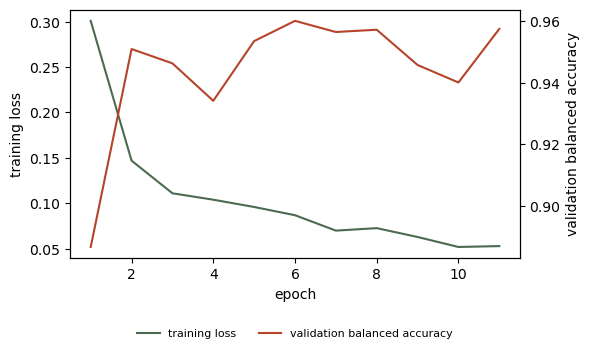

In [9]:
# Training curve (for the Models/Methods page)
h = pd.DataFrame(history)
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(h["epoch"], h["train_loss"], color="#4c6a4f", label="training loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss")
ax2 = ax1.twinx()
ax2.plot(h["epoch"], h["val_balanced_accuracy"], color="#b5442b", label="validation balanced accuracy")
ax2.set_ylabel("validation balanced accuracy")
fig.legend(loc="lower center", ncol=2, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig(os.path.join(OUT_DIR, "part1_training_curve.png"), dpi=150)
plt.show()

## 7. Test on the areas kept aside

This is the first and only time the test areas are used. The scores below are the ones to report.

Test accuracy 0.942, balanced accuracy 0.938
Lost forest: precision 0.963, recall 0.902, F1 0.932
                                  test_patches  accuracy  balanced_accuracy  recall_lost
Brazil                                   305.0     0.954              0.954        0.929
Democratic Republic of the Congo         245.0     0.976              0.962        0.935
India                                    182.0     0.852              0.840        0.690
Indonesia                                318.0     0.956              0.956        0.975


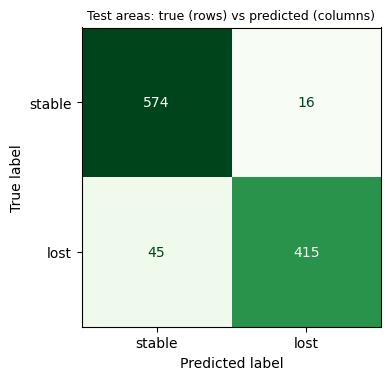

In [10]:
p_test = predict(te)
pred = (p_test > 0.5).astype(int)
yt = y[te]
prec, rec, f1, _ = precision_recall_fscore_support(yt, pred, labels=[0, 1], zero_division=0)
cm = confusion_matrix(yt, pred, labels=[0, 1])

metrics = {
    "model": "ResNet-18, ImageNet-pretrained, 12-band input (Sentinel-2 2018 and 2023)",
    "split": "1-degree map blocks, per country, 70/15/15",
    "test_patches": int(len(te)),
    "accuracy": float(accuracy_score(yt, pred)),
    "balanced_accuracy": float(balanced_accuracy_score(yt, pred)),
    "precision_lost": float(prec[1]), "recall_lost": float(rec[1]), "f1_lost": float(f1[1]),
    "precision_stable": float(prec[0]), "recall_stable": float(rec[0]),
    "confusion_matrix": {"rows_true_cols_predicted": ["stable", "lost"], "values": cm.tolist()},
    "epochs_trained": len(history), "best_validation_balanced_accuracy": float(best),
    "per_country": {},
}
countries_te = meta["country"].to_numpy()[te]
for country in sorted(set(countries_te)):
    m = countries_te == country
    metrics["per_country"][country] = {
        "test_patches": int(m.sum()),
        "accuracy": float(accuracy_score(yt[m], pred[m])),
        "balanced_accuracy": float(balanced_accuracy_score(yt[m], pred[m])),
        "recall_lost": float(precision_recall_fscore_support(yt[m], pred[m], labels=[1], zero_division=0)[1][0]),
    }

print(f"Test accuracy {metrics['accuracy']:.3f}, balanced accuracy {metrics['balanced_accuracy']:.3f}")
print(f"Lost forest: precision {prec[1]:.3f}, recall {rec[1]:.3f}, F1 {f1[1]:.3f}")
print(pd.DataFrame(metrics["per_country"]).T.round(3).to_string())

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(cm, display_labels=["stable", "lost"]).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Test areas: true (rows) vs predicted (columns)", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part1_confusion_matrix.png"), dpi=150)
plt.show()

In [11]:
# Test predictions with locations, for the map
cols = ["patch_id", "country", "lat", "lon", "block", "label"]
out = meta.iloc[te][cols].copy()
out["prob_lost"] = p_test.round(4)
out["predicted"] = pred
out.to_csv(os.path.join(OUT_DIR, "part1_test_predictions.csv"), index=False)
print(f"Saved {len(out)} test predictions")

Saved 1050 test predictions


## 8. A simple comparison model

To show what the neural network adds, we also train a simple, non-deep-learning model on hand-made summary numbers. These are the greenness of each patch (NDVI, which drops when trees are cleared) before and after, the change in greenness, and the average of each band. It uses the same train and test areas.

In [12]:
def ndvi(red, nir):
    return (nir - red) / (nir + red + 1e-6)

def simple_features(idx, chunk=500):
    rows = []
    for s in range(0, len(idx), chunk):          # in chunks, to keep memory use low
        Xi = X[idx[s:s + chunk]].astype(np.float32)
        before, after = ndvi(Xi[:, 2], Xi[:, 3]), ndvi(Xi[:, 8], Xi[:, 9])   # red and near infrared
        change = after - before
        rows.append(np.column_stack([
            before.mean((1, 2)), after.mean((1, 2)), change.mean((1, 2)),
            np.percentile(change, 10, axis=(1, 2)), change.min((1, 2)),
            Xi.mean(axis=(2, 3)),
        ]))
    return np.concatenate(rows)

baseline = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
baseline.fit(simple_features(tr), y[tr])
base_pred = baseline.predict(simple_features(te))
metrics["baseline"] = {
    "model": "logistic regression on greenness (NDVI) change and band averages",
    "accuracy": float(accuracy_score(yt, base_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(yt, base_pred)),
    "confusion_matrix": confusion_matrix(yt, base_pred, labels=[0, 1]).tolist(),
}
print(pd.DataFrame({
    "ResNet-18": [metrics["accuracy"], metrics["balanced_accuracy"]],
    "Simple model": [metrics["baseline"]["accuracy"], metrics["baseline"]["balanced_accuracy"]],
}, index=["accuracy", "balanced accuracy"]).round(3))

metrics["history"] = history
with open(os.path.join(OUT_DIR, "part1_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
print("Saved", os.path.join(OUT_DIR, "part1_metrics.json"))

                   ResNet-18  Simple model
accuracy               0.942         0.890
balanced accuracy      0.938         0.881
Saved ../outputs/part1_metrics.json


## 9. What these scores do and don't show

- **The test patches are clear-cut cases.** Step 1 kept only patches that were clearly lost (at least 10% cleared) or clearly stable. Real landscapes include many in-between squares, so accuracy on a random square of forest would likely be lower.
- **The labels come from another model.** Hansen's forest-loss map is itself made from satellite data and has its own mistakes, so "accuracy" means agreement with Hansen, not with ground surveys.
- **Countries differ.** DR Congo and India have fewer lost patches because clearing there is often small-scale, so their per-country scores rest on fewer examples. That difference is a finding in itself.
- **Neighbouring blocks.** Whole blocks are kept apart, but two patches on either side of a block edge can still be close together. With ~110 km blocks this affects only a small share of patches.
- **One run.** The scores come from one training run with one split. A different split or seed would move them a little.

## Sources and credits

- Sentinel-2 imagery: contains modified Copernicus Sentinel data (2018, 2023), via Google Earth Engine.
- Forest-loss labels: Hansen, M. C. et al. (2013), *High-Resolution Global Maps of 21st-Century Forest Cover Change*, Science 342, v1.11 (CC BY 4.0).
- ResNet-18: He, K. et al. (2016), *Deep Residual Learning for Image Recognition*. Pretrained weights from torchvision (BSD-3-Clause).